<a href="https://colab.research.google.com/github/Sanhith30/ITA0605-ML/blob/main/Lab%20Exercises/Exp01_FIND_S.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 1: FIND-S Algorithm
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Implement and demonstrate the FIND-S algorithm for finding the most specific hypothesis based on a given set of training data samples.

## Background
FIND-S starts with the most specific hypothesis `<0,0,...,0>` and, for every **positive** training example, generalises the hypothesis just enough to cover it. Negative examples are ignored. The result is the **maximally specific hypothesis** consistent with the positive examples (assuming the data is noise-free and the target concept is a conjunction of attribute constraints). `?` means *any value is acceptable* and `0` means *no value is acceptable*.

## Pipeline followed in this notebook
1. Step 1: Data Collection
2. Step 2: Data Loading
3. Step 3: Data Preprocessing
4. Step 4: Exploratory Data Analysis (EDA)
5. Step 5: Model Training (FIND-S)
6. Step 6: Model Evaluation
7. Step 7: Prediction on New Data

> **How to run:** Open in Google Colab -> *Runtime -> Run all*. No files need to be uploaded; the data is created or loaded inside the notebook.

## Setup: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
np.random.seed(42)
print("Libraries imported successfully")

Libraries imported successfully


## Step 1: Data Collection
We use the classic **EnjoySport** concept-learning dataset (Tom Mitchell). Each row describes the weather and whether a person enjoys their sport. We build it in code and save it as a CSV, exactly like data collected from a file.

In [2]:
data = [
    ["Sunny", "Warm", "Normal", "Strong", "Warm", "Same",   "Yes"],
    ["Sunny", "Warm", "High",   "Strong", "Warm", "Same",   "Yes"],
    ["Rainy", "Cold", "High",   "Strong", "Warm", "Change", "No"],
    ["Sunny", "Warm", "High",   "Strong", "Cool", "Change", "Yes"],
]
columns = ["Sky", "AirTemp", "Humidity", "Wind", "Water", "Forecast", "EnjoySport"]

pd.DataFrame(data, columns=columns).to_csv("enjoysport.csv", index=False)
print("Dataset saved to enjoysport.csv")

Dataset saved to enjoysport.csv


## Step 2: Data Loading
Load the CSV into a pandas DataFrame and take a first look.

In [3]:
df = pd.read_csv("enjoysport.csv")
print("Shape:", df.shape)
df

Shape: (4, 7)


,Sky,AirTemp,Humidity,Wind,Water,Forecast,EnjoySport
0,Sunny,Warm,Normal,Strong,Warm,Same,Yes
1,Sunny,Warm,High,Strong,Warm,Same,Yes
2,Rainy,Cold,High,Strong,Warm,Change,No
3,Sunny,Warm,High,Strong,Cool,Change,Yes


## Step 3: Data Preprocessing
Clean whitespace, check for missing values and split the data into attributes (`X`) and the target label (`y`).

In [4]:
df = df.apply(lambda col: col.str.strip())      # remove stray spaces
print("Missing values:\n", df.isnull().sum())

attributes = list(df.columns[:-1])
X = df[attributes].values
y = df["EnjoySport"].values
print("\nAttributes:", attributes)
print("Positive examples:", (y == "Yes").sum(), "| Negative examples:", (y == "No").sum())

Missing values:
 Sky           0
AirTemp       0
Humidity      0
Wind          0
Water         0
Forecast      0
EnjoySport    0
dtype: int64

Attributes: ['Sky', 'AirTemp', 'Humidity', 'Wind', 'Water', 'Forecast']
Positive examples: 3 | Negative examples: 1


## Step 4: Exploratory Data Analysis (EDA)
Look at how each attribute value relates to the target. FIND-S only learns from the positive rows, so it is useful to see which values appear there.

In [5]:
print(df.describe(include="all").T)
print()
for col in attributes:
    print(df.groupby([col, "EnjoySport"]).size().unstack(fill_value=0), "\n")

           count unique     top freq
Sky            4      2   Sunny    3
AirTemp        4      2    Warm    3
Humidity       4      2    High    3
Wind           4      1  Strong    4
Water          4      2    Warm    3
Forecast       4      2    Same    2
EnjoySport     4      2     Yes    3

EnjoySport  No  Yes
Sky                
Rainy        1    0
Sunny        0    3 

EnjoySport  No  Yes
AirTemp            
Cold         1    0
Warm         0    3 

EnjoySport  No  Yes
Humidity           
High         1    2
Normal       0    1 

EnjoySport  No  Yes
Wind               
Strong       1    3 

EnjoySport  No  Yes
Water              
Cool         0    1
Warm         1    2 

EnjoySport  No  Yes
Forecast           
Change       1    1
Same         0    2 



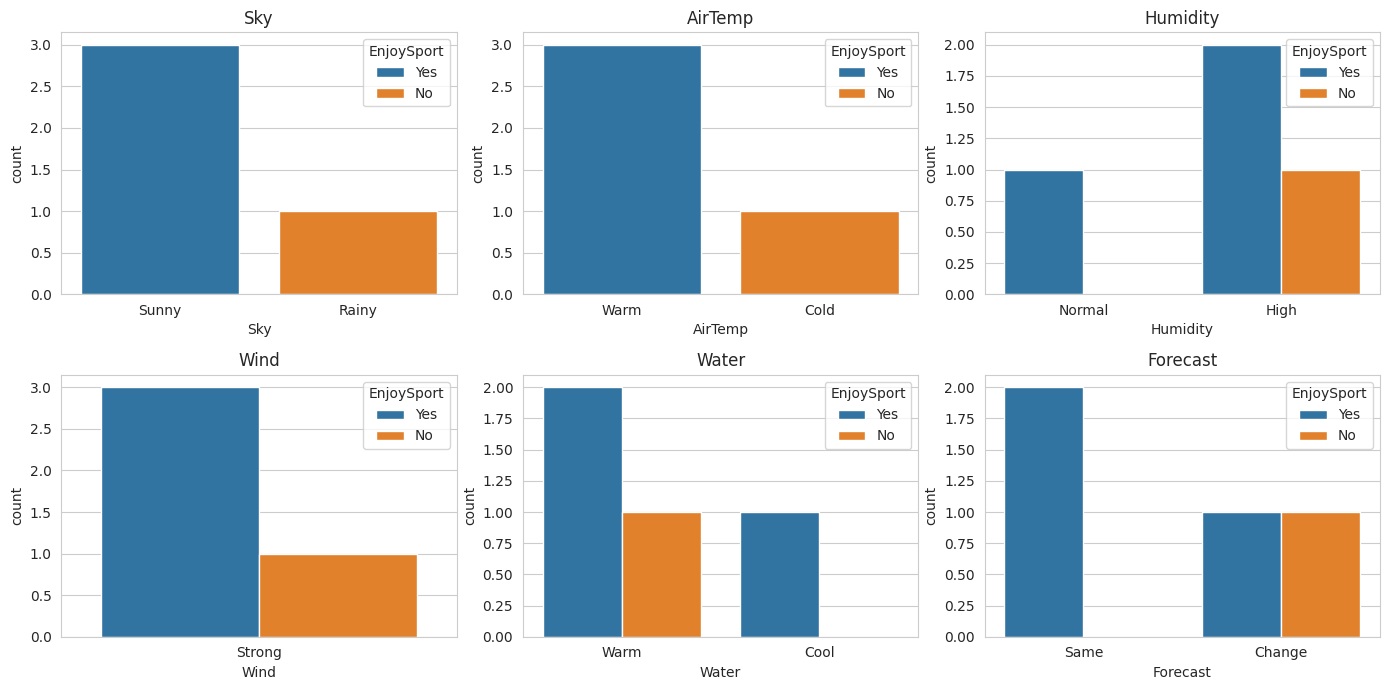

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), attributes):
    sns.countplot(data=df, x=col, hue="EnjoySport", ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## Step 5: Model Training (FIND-S)
Implementation of FIND-S. We print the hypothesis after every training example so the learning process is visible.

In [7]:
def find_s(X, y):
    n = X.shape[1]
    h = ["0"] * n                       # most specific hypothesis
    trace = [("initial", h.copy())]
    for i, (xi, yi) in enumerate(zip(X, y), 1):
        if yi == "Yes":                 # only positive examples are used
            for j in range(n):
                if h[j] == "0":
                    h[j] = xi[j]
                elif h[j] != xi[j]:
                    h[j] = "?"
        trace.append((f"example {i} ({yi})", h.copy()))
    return h, trace

hypothesis, trace = find_s(X, y)
for step, h in trace:
    print(f"{step:<18} -> {h}")
print("\nMost specific hypothesis found:", hypothesis)

initial            -> ['0', '0', '0', '0', '0', '0']
example 1 (Yes)    -> ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same']
example 2 (Yes)    -> ['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']
example 3 (No)     -> ['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']
example 4 (Yes)    -> ['Sunny', 'Warm', '?', 'Strong', '?', '?']

Most specific hypothesis found: ['Sunny', 'Warm', '?', 'Strong', '?', '?']


## Step 6: Model Evaluation
A correct FIND-S hypothesis must cover **every positive** example. We also check how it behaves on the negative examples and compute accuracy and the confusion matrix on the training data.

Accuracy: 1.0

Classification report:
               precision    recall  f1-score   support

          No       1.00      1.00      1.00         1
         Yes       1.00      1.00      1.00         3

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



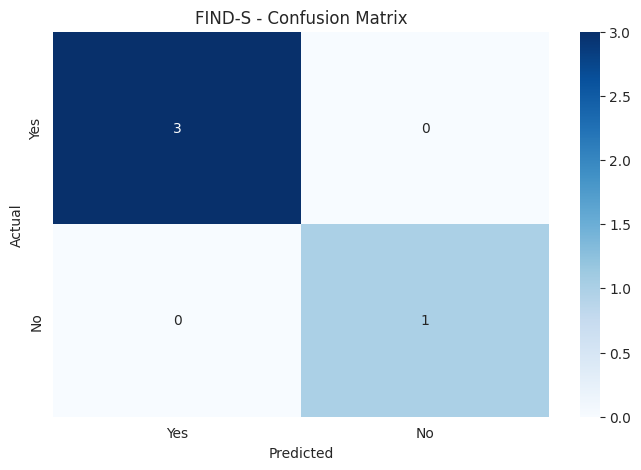

In [8]:
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

def matches(h, x):
    return all(hv == "?" or hv == xv for hv, xv in zip(h, x))

y_pred = np.array(["Yes" if matches(hypothesis, x) else "No" for x in X])

print("Accuracy:", accuracy_score(y, y_pred))
print("\nClassification report:\n", classification_report(y, y_pred))

cm = confusion_matrix(y, y_pred, labels=["Yes", "No"])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Yes", "No"], yticklabels=["Yes", "No"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("FIND-S - Confusion Matrix")
plt.show()

## Step 7: Prediction on New Data
Use the learned hypothesis to classify unseen weather conditions.

In [9]:
new_samples = [
    ["Sunny", "Warm", "Normal", "Strong", "Cool", "Change"],
    ["Rainy", "Warm", "High",   "Strong", "Warm", "Same"],
    ["Sunny", "Warm", "High",   "Weak",   "Warm", "Same"],
]
for s in new_samples:
    print(s, "->", "Yes" if matches(hypothesis, s) else "No")

['Sunny', 'Warm', 'Normal', 'Strong', 'Cool', 'Change'] -> Yes
['Rainy', 'Warm', 'High', 'Strong', 'Warm', 'Same'] -> No
['Sunny', 'Warm', 'High', 'Weak', 'Warm', 'Same'] -> No


## Conclusion
FIND-S produced the maximally specific hypothesis `<Sunny, Warm, ?, Strong, ?, ?>`, which covers all positive examples. **Limitations:** it ignores negative examples, cannot detect noisy data and returns only one hypothesis even if several are consistent. The Candidate-Elimination algorithm (Experiment 2) overcomes these issues.